# CARSE mmWave Notebook – IWR6843ISK + MMWAVEICBOOST

This notebook will server as a pipeline to process recorded data from the provided mmWave board.

The code ran in this notebook is located inside the lib/ folder (.py files).

Estimated BPM: 12.0
Quality: High


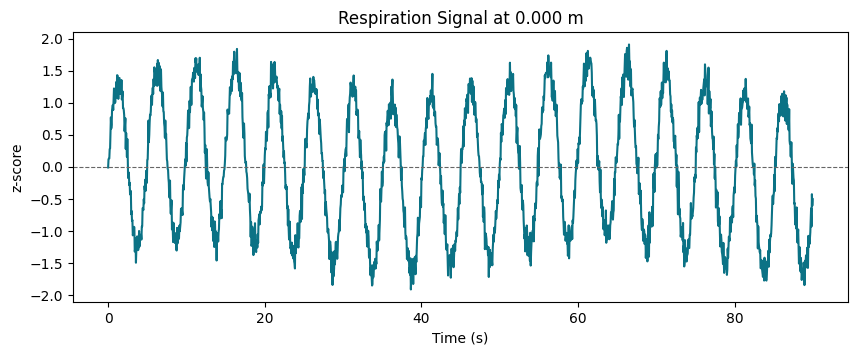

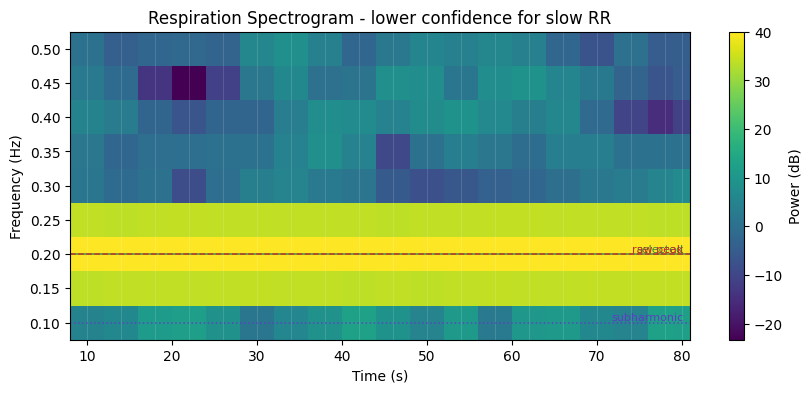

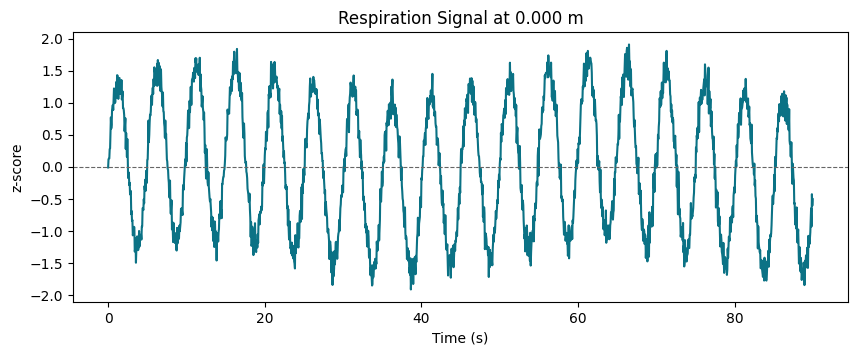

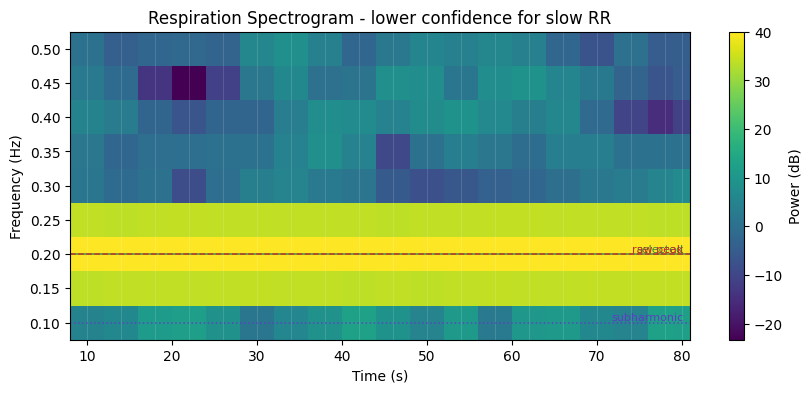

In [1]:
from lib.synthetic_respiration_validation import (
    generate_synthetic_respiration_signal
)

from lib.respiration_pipeline import build_respiration_features

from lib.visualization_pipeline import (
    plot_respiration_signal,
    plot_respiration_spectrogram,
    compute_respiration_spectrogram,
)

from IPython.display import display

# Generate a 90-second, 12 BPM respiration signal
signal = generate_synthetic_respiration_signal(
    bpm=12.0,
    duration_s=90.0,
    sample_rate_hz=20.0,
)

# Compute time-frequency representation
spectrogram = compute_respiration_spectrogram(
    signal,
    min_frequency_hz=4 / 60,
    max_frequency_hz=30 / 60,
)

# Extract respiration features
features = build_respiration_features(
    signal,
    spectrogram=spectrogram,
    min_bpm=4.0,
    max_bpm=30.0,
)

# Show the detected rate
print("Estimated BPM:", features["global_bpm"])
print("Quality:", features["quality_label"])

# Display the plots
fig1, ax1 = plot_respiration_signal(signal)
display(fig1)

fig2, ax2, spec = plot_respiration_spectrogram(
    signal,
    min_frequency_hz=4 / 60,
    max_frequency_hz=30 / 60,
    features=features,
)
display(fig2)

## Step 1: Turn the recording into readable data

The `.dat` file in `ref/data/` is a processed UART stream from the Out-of-Box demo, not raw ADC samples.

So the first useful step is:

1. parse the `.cfg` file so we know the recording setup
2. parse the `.dat` file into frames and detected objects
3. export detections to CSV so the data is easy to inspect outside the visualizer

The notebook stays thin on purpose.

Most of the logic now lives in:

- `lib/parser_mmw_demo.py` for packet parsing
- `lib/capture_pipeline.py` for loading, summarizing, and exporting the capture

In [2]:
from pprint import pprint

from lib.capture_pipeline import build_capture_overview, load_latest_capture

bundle = load_latest_capture()
overview = build_capture_overview(bundle)

print("Config file:", overview["config_file"])
print("Data file:", overview["data_file"])
print("\nCapture summary:")
pprint(overview["summary"])

print("\nConfig metadata:")
pprint(overview["config_metadata"])

print("\nFirst 8 CLI commands:")
for command in overview["first_commands"]:
    print(command)

print("\nFirst frame header:")
pprint(overview["first_frame_header"])

print("\nFirst frame TLVs:")
pprint(overview["first_frame_tlvs"])

Config file: xwr68xx_profile_2026_04_29T01_27_26_533.cfg
Data file: xwr68xx_processed_stream_2026_04_29T01_26_26_495.dat

Capture summary:
{'frame_count': 1802,
 'max_points_in_frame': 4,
 'non_empty_frame_count': 1798,
 'total_detected_points': 3876}

Config metadata:
{'Azimuth Resolution(deg)': '15',
 'Created for SDK ver': '03.06',
 'Created using Visualizer ver': '3.6.0.0',
 'Frame Duration(msec)': '33.333',
 'Frequency': '60',
 'Maximum Radial Velocity(m/s)': '1.21',
 'Maximum unambiguous Range(m)': '5',
 'Platform': 'xWR68xx',
 'RF calibration data': 'None',
 'Radial velocity resolution(m/s)': '0.16',
 'Range Resolution(m)': '0.098',
 'Scene Classifier': 'best_range'}

First 8 CLI commands:
{'command': 'sensorStop', 'args': []}
{'command': 'flushCfg', 'args': []}
{'command': 'dfeDataOutputMode', 'args': ['1']}
{'command': 'channelCfg', 'args': ['15', '5', '0']}
{'command': 'adcCfg', 'args': ['2', '1']}
{'command': 'adcbufCfg', 'args': ['-1', '0', '1', '1', '1']}
{'command': 'prof

In [3]:
from pprint import pprint

from lib.capture_pipeline import export_capture_readables

readable = export_capture_readables(bundle)

print(f"Exported {readable['num_rows']} detection rows to {readable['output_csv']}")

print("\nFirst 5 detection rows:")
for row in readable["first_detection_rows"]:
    pprint(row)

print("\nPoints per frame (first 20 frames):")
print(readable["points_per_frame_head"])

if readable["first_range_profile_bins"]:
    print("\nFirst 10 range-profile bins from frame 0:")
    print(readable["first_range_profile_bins"])

if readable["first_frame_stats"] is not None:
    print("\nFirst frame stats:")
    pprint(readable["first_frame_stats"])

Exported 3876 detection rows to c:\Users\drago\Documents\Projecto CARSE mmWave\Documentacion CARSE mmWave\mmWave Pipeline\ref\data\xwr68xx_processed_stream_2026_04_29T01_26_26_495_detections.csv

First 5 detection rows:
{'azimuth_deg': -75.63848152497962,
 'elevation_deg': 0.0,
 'frame': 424641,
 'noise': 862,
 'point_index': 0,
 'range_m': 0.09766472841265435,
 'snr': 169,
 'subframe': 0,
 'velocity': 0.0,
 'x': -0.09461270272731781,
 'y': 0.024224691092967987,
 'z': 0.0}
{'azimuth_deg': -75.63848152497962,
 'elevation_deg': 0.0,
 'frame': 424642,
 'noise': 859,
 'point_index': 0,
 'range_m': 0.09766472841265435,
 'snr': 172,
 'subframe': 0,
 'velocity': 0.0,
 'x': -0.09461270272731781,
 'y': 0.024224691092967987,
 'z': 0.0}
{'azimuth_deg': -75.63848152497962,
 'elevation_deg': 0.0,
 'frame': 424643,
 'noise': 863,
 'point_index': 0,
 'range_m': 0.09766472841265435,
 'snr': 168,
 'subframe': 0,
 'velocity': 0.0,
 'x': -0.09461270272731781,
 'y': 0.024224691092967987,
 'z': 0.0}
{'azim

## Step 2: Extract a first respiration signal

Detected objects are intermittent, so they are not the best continuous breathing signal.

A better next step is to use the per-frame range profile:

1. rank range bins by how much they vary over time
2. pick a candidate range gate
3. aggregate a small bin window around that gate
4. export the result as a time series

The helper below auto-selects a candidate bin, but you can override it later with `center_bin=` or `center_range_m=` if needed.

In [4]:
from importlib import reload
from pprint import pprint
from pathlib import Path

import lib.respiration_pipeline as respiration_pipeline

reload(respiration_pipeline)

bin_summary = respiration_pipeline.summarize_range_bins(bundle, min_bin=3, top_k=12)
resp_signal = respiration_pipeline.extract_respiration_signal(
    bundle,
    bin_half_width=1,
    min_bin=3,
    selection_top_k=12,
 )

resp_csv = Path(bundle.data_path).with_name(f"{Path(bundle.data_path).stem}_respiration_signal.csv")
respiration_pipeline.export_respiration_signal_csv(resp_signal, resp_csv)

print("Top variable range-bin candidates:")
pprint(bin_summary["top_variable_bins"])

print("\nAuto gate-selection details:")
pprint({
    "selection_method": resp_signal["selection_method"],
    "candidate_bins": resp_signal["selection_candidate_bins"],
    "cluster_bins": resp_signal["selection_cluster_bins"],
    "weighted_center_bin": resp_signal["selection_weighted_center_bin"],
})

print("\nSelected range gate:")
print({
    "center_bin": resp_signal["center_bin"],
    "center_range_m": resp_signal["center_range_m"],
    "selected_bins": resp_signal["selected_bins"],
    "selected_ranges_m": resp_signal["selected_ranges_m"],
})

print("\nFirst 10 raw respiration-signal samples:")
print(resp_signal["raw_signal"][:10])

print("\nFirst 10 centered respiration-signal samples:")
print(resp_signal["centered_signal"][:10])

print("\nExported respiration signal CSV:")
print(resp_csv)

Top variable range-bin candidates:
[{'bin_index': 7,
  'mean': 3985.5754716981132,
  'range_m': 0.686,
  'std': 168.4081115290266},
 {'bin_index': 6,
  'mean': 3492.227524972253,
  'range_m': 0.5880000000000001,
  'std': 145.02714873625146},
 {'bin_index': 8,
  'mean': 4179.758046614872,
  'range_m': 0.784,
  'std': 116.83520582827148},
 {'bin_index': 10,
  'mean': 3774.8157602663705,
  'range_m': 0.98,
  'std': 109.38733334911308},
 {'bin_index': 9,
  'mean': 4074.8085460599336,
  'range_m': 0.882,
  'std': 109.32074342782813},
 {'bin_index': 43,
  'mean': 3203.2130965593783,
  'range_m': 4.214,
  'std': 104.41244671670152},
 {'bin_index': 52,
  'mean': 2902.5460599334074,
  'range_m': 5.096,
  'std': 93.8177226412483},
 {'bin_index': 14,
  'mean': 3329.8002219755826,
  'range_m': 1.372,
  'std': 90.11711482270438},
 {'bin_index': 5,
  'mean': 3189.4428412874586,
  'range_m': 0.49,
  'std': 88.54291149963811},
 {'bin_index': 50,
  'mean': 2925.9017758046616,
  'range_m': 4.9,
  'std':

## Step 3: Visualize what this recording actually contains

This capture is good for three immediate views:

1. a range-time waterfall built from the range profile
2. the extracted respiration signal over time
3. a spectrogram of that respiration signal

So for this recording, the right mental model is:

- waterfall = how reflectivity changes with **range and time**
- spectrogram = how the extracted breathing signal changes with **frequency and time**
- Doppler heatmap = unavailable here, and must be captured explicitly in a future recording

## Visualization Summary

| View | Status |
| --- | --- |
| Range-time waterfall | Available |
| Respiration signal and spectrogram | Available |
| True range-Doppler heatmap | Unavailable |

Note: This recording does not contain a true range-Doppler heatmap TLV. You can still plot range-vs-time heatmaps and respiration spectrograms from the recorded range profiles.

## Spectrogram Settings

| Setting | Value |
| --- | --- |
| Min frequency | 0.067 Hz (4.0 BPM) |
| Max frequency | 0.500 Hz (30.0 BPM) |
| Sample rate | 30.000 Hz |
| Window mode | manual |
| Window seconds | 20.0 s |
| Hop seconds | 4.0 s |
| Window size | 600 samples |
| Hop size | 120 samples |
| Frequency bins | 8 |
| Frequency resolution | 3.00 BPM/bin |
| Reliable at slow limit | No |
| Time slices | 12 |

## Spectrogram Notes

- Visual spectrogram window uses 20.0 s with 4.0 s hop to show more time slices across mixed BPM recordings. It contains 1.33 cycles at 4.0 BPM and 2.67 cycles at 8.0 BPM. Use the longer respiration-aware window for primary slow-BPM estimation.
- This spectrogram window is useful for visualization but lower-confidence for slow-BPM estimation.
- Frequency resolution is 3.00 BPM per bin, so very slow breathing can quantize to nearby bins.

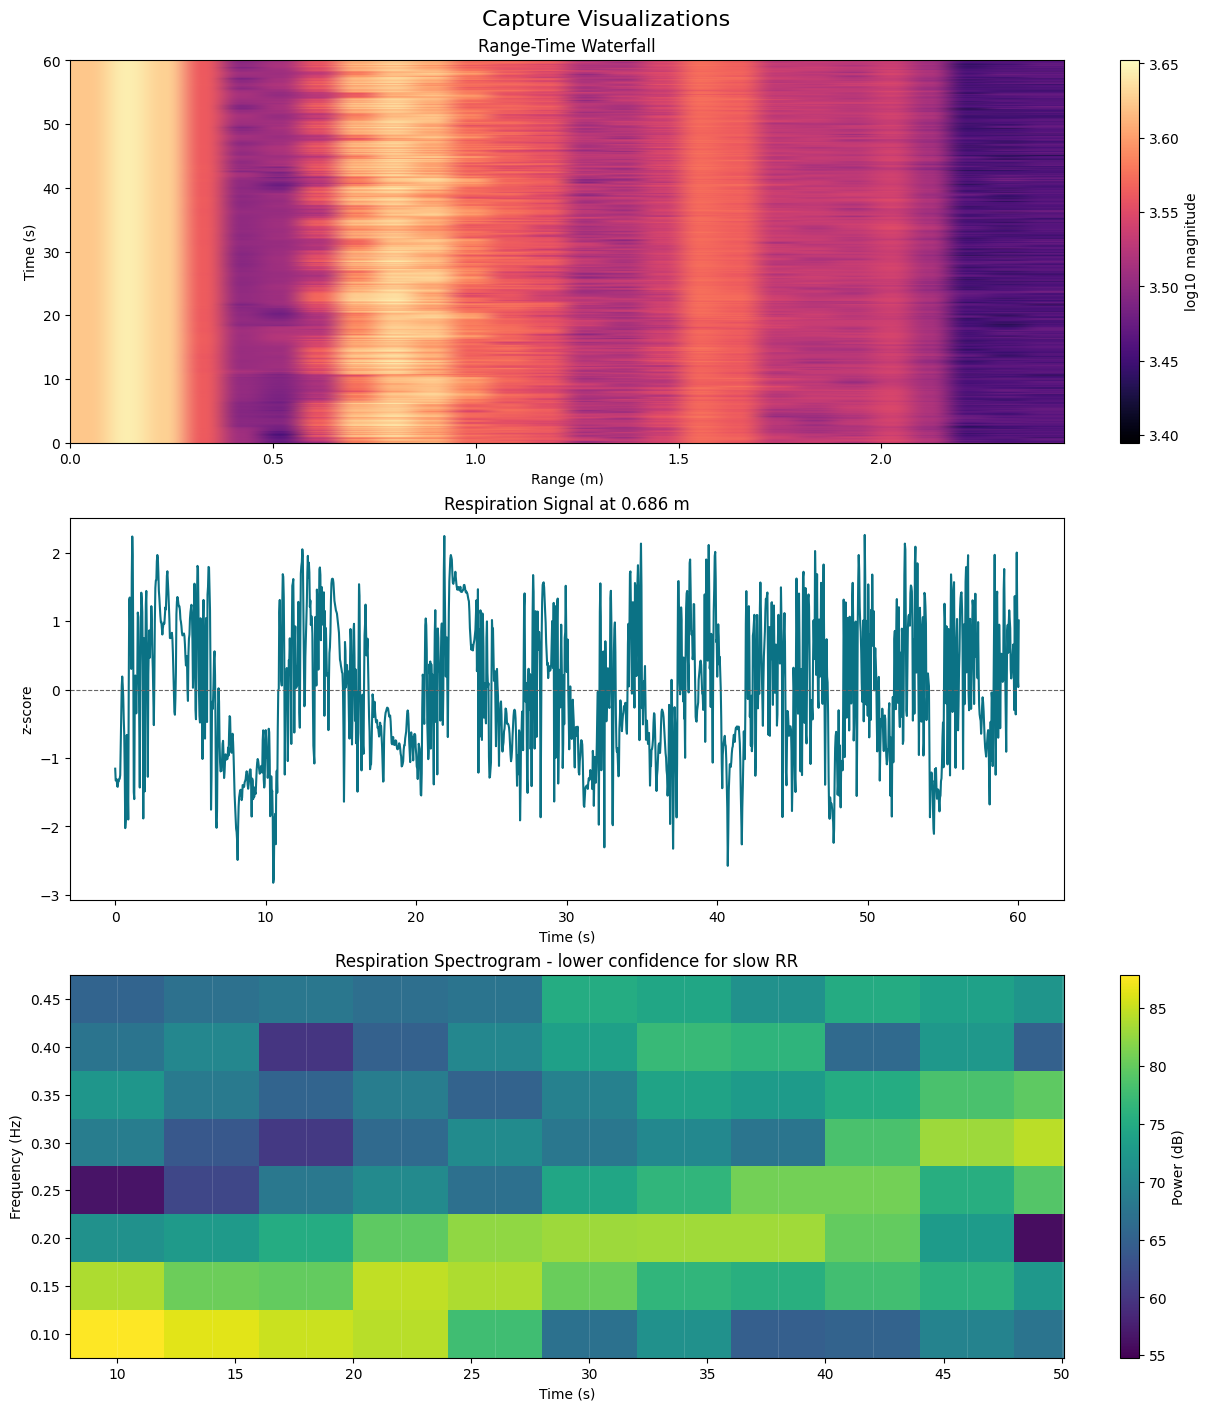

In [5]:
from importlib import reload
from IPython.display import Markdown, display

import lib.respiration_pipeline as respiration_pipeline
import lib.visualization_pipeline as visualization_pipeline

reload(respiration_pipeline)
reload(visualization_pipeline)

analysis_min_bpm = 4.0
analysis_max_bpm = 30.0

signal_duration_s = resp_signal["times_s"][-1] + resp_signal["frame_period_s"] if resp_signal["times_s"] else 0.0
window_choice = visualization_pipeline.choose_respiration_visual_window_seconds(
    signal_duration_s,
    min_bpm=analysis_min_bpm,
    max_bpm=analysis_max_bpm,
)
spectrogram_window_seconds = window_choice["window_seconds"]
spectrogram_hop_seconds = window_choice["hop_seconds"]

figure, axes, viz_info, spectrogram = visualization_pipeline.plot_capture_dashboard(
    bundle,
    resp_signal,
    max_range_m=2.5,
    min_frequency_hz=analysis_min_bpm / 60.0,
    max_frequency_hz=analysis_max_bpm / 60.0,
    spectrogram_window_seconds=spectrogram_window_seconds,
    spectrogram_hop_seconds=spectrogram_hop_seconds,
    use_respiration_window=False,
    min_bpm=analysis_min_bpm,
    max_bpm=analysis_max_bpm,
 )

frequency_resolution_bpm = spectrogram.get("frequency_resolution_bpm")

spectrogram_notes = []
spectrogram_notes.append(window_choice["decision_reason"])
if not window_choice["reliable_for_min_bpm"]:
    spectrogram_notes.append("This spectrogram window is useful for visualization but lower-confidence for slow-BPM estimation.")
if frequency_resolution_bpm is not None and frequency_resolution_bpm >= 2.0:
    spectrogram_notes.append(
        f"Frequency resolution is {frequency_resolution_bpm:.2f} BPM per bin, so very slow breathing can quantize to nearby bins."
    )
if len(spectrogram["times_s"]) < 3:
    spectrogram_notes.append(
        "There are too few spectrogram time slices for a detailed slow-breathing timeline. The global BPM is more trustworthy than the spectrogram here."
    )

viz_report_lines = [
    "## Visualization Summary",
    "",
    "| View | Status |",
    "| --- | --- |",
    f"| Range-time waterfall | {'Available' if viz_info['can_plot_range_profile_waterfall'] else 'Unavailable'} |",
    f"| Respiration signal and spectrogram | {'Available' if viz_info['can_plot_respiration_signal'] else 'Unavailable'} |",
    f"| True range-Doppler heatmap | {'Available' if viz_info['can_plot_true_range_doppler_heatmap'] else 'Unavailable'} |",
    "",
    f"Note: {viz_info['doppler_heatmap_note']}",
    "",
    "## Spectrogram Settings",
    "",
    "| Setting | Value |",
    "| --- | --- |",
    f"| Min frequency | {analysis_min_bpm / 60.0:.3f} Hz ({analysis_min_bpm:.1f} BPM) |",
    f"| Max frequency | {analysis_max_bpm / 60.0:.3f} Hz ({analysis_max_bpm:.1f} BPM) |",
    f"| Sample rate | {spectrogram['sample_rate_hz']:.3f} Hz |",
    f"| Window mode | {spectrogram.get('window_mode', '-')} |",
    f"| Window seconds | {spectrogram['window_seconds']:.1f} s |",
    f"| Hop seconds | {spectrogram['hop_seconds']:.1f} s |",
    f"| Window size | {spectrogram['window_size']} samples |",
    f"| Hop size | {spectrogram['hop_size']} samples |",
    f"| Frequency bins | {len(spectrogram['frequencies_hz'])} |",
    f"| Frequency resolution | {'-' if frequency_resolution_bpm is None else f'{frequency_resolution_bpm:.2f} BPM/bin'} |",
    f"| Reliable at slow limit | {'Yes' if spectrogram['reliable_for_min_bpm'] else 'No'} |",
    f"| Time slices | {len(spectrogram['times_s'])} |",
]

if spectrogram_notes:
    viz_report_lines.extend([
        "",
        "## Spectrogram Notes",
        "",
    ])
    viz_report_lines.extend(f"- {note}" for note in spectrogram_notes)

display(Markdown("\n".join(viz_report_lines)))

## Step 4: Extract quantitative respiration features

The plots are useful qualitatively, but it is better to also compute explicit features from the extracted respiration signal.

This step reports:

1. the selected subject range gate
2. one overall BPM estimate from the full 60 s signal
3. a coarse BPM-over-time summary from the spectrogram
4. the strongest candidate frequency peaks in the breathing band

For slow breathing, the global BPM estimate is usually the most stable number. The spectrogram-derived BPM values are still helpful, but they are coarser because they come from finite time windows.

In [6]:
from importlib import reload
from IPython.display import Markdown, display

import lib.respiration_pipeline as respiration_pipeline
import lib.visualization_pipeline as visualization_pipeline

reload(respiration_pipeline)
reload(visualization_pipeline)

analysis_min_bpm = globals().get("analysis_min_bpm", 4.0)
analysis_max_bpm = globals().get("analysis_max_bpm", 60.0)

feature_spectrogram = visualization_pipeline.compute_respiration_spectrogram(
    resp_signal,
    min_frequency_hz=analysis_min_bpm / 60.0,
    max_frequency_hz=analysis_max_bpm / 60.0,
    use_respiration_window=False,
    min_bpm=analysis_min_bpm,
    max_bpm=analysis_max_bpm,
 )

resp_features = respiration_pipeline.build_respiration_features(
    resp_signal,
    spectrogram=feature_spectrogram,
    min_bpm=analysis_min_bpm,
    max_bpm=analysis_max_bpm,
 )

feature_report = respiration_pipeline.format_respiration_feature_report(
    resp_features,
    bpm_preview_count=20,
 )

display(Markdown(feature_report))

## Respiration Summary

| Metric | Value |
| --- | --- |
| Selected center bin | 7 |
| Selected center range | 0.686 m |
| Selected bins | 6, 7, 8 |
| Range-bin selection | auto-respiration-band-trend |
| Large range motion detected | No |
| Dynamic range tracking used | No |
| Tracked range early/mid/late | 1.57 / 1.86 / 1.76 m |
| Tracked range span | 1.18 m |
| Fixed gate matches tracked target | No |
| Duration | 60.1 s |
| Sample rate | 30.000 Hz |
| Recording type | nonstationary |
| Respiration pattern | nonstationary_transition |
| Reported transition pattern | multi_stage |
| Final selected RR | 10.99 BPM |
| Final selected frequency | 0.1831 Hz |
| Global BPM representative | No |
| Global BPM confidence | 0.35 |
| Early BPM | 5.99 |
| Mid BPM | 11.98 |
| Late BPM | 18.00 |
| BPM change magnitude | 12.01 |
| Transition detected | Yes |
| Transition time | 35.0 s |
| Trend confidence | 0.94 |
| Transition confidence | 0.94 |
| Raw strongest spectral peak | 10.99 BPM |
| Raw strongest frequency | 0.1831 Hz |
| Autocorrelation estimate | 6.08 BPM |
| Time-domain estimate | 17.65 BPM |
| Time-domain period | 3.40 s |
| Time-domain breaths detected | 7 |
| Time-domain confidence | 0.79 |
| Harmonic suspected | No |
| Harmonic correction | Not applied |
| Subharmonic power ratio | 0.35 |
| Ambiguous result | No |
| Selected BPM source | global_fft |
| Quality | High |
| Final confidence | 0.90 |
| Signal quality score | 1.00 |
| Spectral confidence | 0.50 |
| Temporal consistency score | 0.94 |
| Harmonic ambiguity score | 1.00 |
| Peak confidence ratio | 1.36 |
| Chosen window | 45.0 s |
| Chosen hop | 11.2 s |
| Window frequency resolution | 1.33 BPM |
| Window reliable for slow limit | Yes |
| Signal peak-to-peak | 5.08 z-score |
| Signal RMS | 132.00 centered units |

Decision: Raw strongest spectral peak is 10.99 BPM (0.1831 Hz). The 5.49 BPM subharmonic has 0.35x the raw-peak power. The lower 2x-related candidate was not sufficiently supported, so the raw spectral peak was kept.

Nonstationary recording: the global BPM is a summary of the whole capture, not a single representative breathing rate.
Trend: Best transition split at 35.0 s separates 6.22 BPM before from 18.42 BPM after (12.20 BPM change), exceeding the 4.00 BPM transition threshold.

Window choice: Window contains about 3.0 cycles at the slow limit (4.0 BPM).

Range-bin choice: Selected a respiration-band candidate whose early/late segment estimates show the clearest sustained rate transition.

Range-motion diagnostic: No large target range migration was detected. Tracked residual range changed by 0.20 m (1.57 m early to 1.76 m late); 10th-90th percentile span is 1.18 m.

Quality flags: nonstationary breathing, rate transition detected, wide BPM spread from transition

## Time-Varying BPM Summary

| Metric | Value |
| --- | --- |
| Median BPM | 12.00 |
| 10th percentile BPM | 6.00 |
| 90th percentile BPM | 18.00 |
| BPM spread | 12.00 |
| Min BPM | 6.00 |
| Max BPM | 18.00 |

## Segmented BPM Summary

| Segment | Time span (s) | BPM | Confidence | Raw spectral BPM | Time-domain BPM |
| --- | --- | --- | --- | --- | --- |
| before_35.0s | 0.0-35.0 | 6.22 | 0.91 | 6.85 | 6.08 |
| after_35.0s | 35.0-60.1 | 18.42 | 0.77 | 19.17 | 17.82 |
| early | 0.0-20.0 | 5.99 | 0.55 | 5.99 | 9.38 |
| mid | 20.0-40.0 | 11.76 | 0.55 | 11.98 | 5.08 |
| late | 40.0-60.1 | 17.86 | 0.96 | 18.00 | 17.65 |

## Multi-Window Estimates

| Source | Window (s) | Median BPM | BPM range | Reliable for slow limit |
| --- | --- | --- | --- | --- |
| global_fft | 60.1 | 10.99 | 10.99-10.99 | Yes |
| long_window | 45.0 | 12.00 | 7.73-12.00 | Yes |
| medium_window | 30.0 | 12.00 | 7.00-18.00 | Yes |
| short_responsive | 15.0 | 12.00 | 4.00-19.20 | No |

## Strongest Global Peaks

| Rank | BPM | Frequency (Hz) | Relative Power |
| --- | --- | --- | --- |
| 1 | 10.99 | 0.1831 | 1.000 |
| 2 | 11.99 | 0.1998 | 0.734 |
| 3 | 7.99 | 0.1332 | 0.416 |
| 4 | 9.99 | 0.1665 | 0.362 |
| 5 | 5.99 | 0.0999 | 0.348 |

## First 12 BPM-Over-Time Windows

| Window center (s) | BPM |
| --- | --- |
| 10.0 | 6.00 |
| 14.0 | 6.00 |
| 18.0 | 6.00 |
| 22.0 | 6.00 |
| 26.0 | 9.00 |
| 30.0 | 12.00 |
| 34.0 | 12.00 |
| 38.0 | 12.00 |
| 42.0 | 15.00 |
| 46.0 | 18.00 |
| 50.0 | 18.00 |
| 50.1 | 18.00 |

## Step 5: Compare the latest 3 recordings

This step loads the three most recent `.cfg`/`.dat` pairs and summarizes them side by side.

It is useful when you want to compare the selected range gate and respiration-rate estimate across multiple short recordings without changing the rest of the notebook flow.

In [7]:
from importlib import reload
from statistics import median
from IPython.display import Markdown, display

import lib.capture_pipeline as capture_pipeline
import lib.respiration_pipeline as respiration_pipeline
import lib.visualization_pipeline as visualization_pipeline

reload(capture_pipeline)
reload(respiration_pipeline)
reload(visualization_pipeline)

comparison_min_bpm = globals().get("analysis_min_bpm", 4.0)
comparison_max_bpm = globals().get("analysis_max_bpm", 60.0)
comparison_rows = []

for recent_bundle in capture_pipeline.load_recent_captures(limit=3):
    try:
        recent_signal = respiration_pipeline.extract_respiration_signal(
            recent_bundle,
            min_bin=3,
            bin_half_width=1,
        )
        recent_spectrogram = visualization_pipeline.compute_respiration_spectrogram(
            recent_signal,
            min_frequency_hz=comparison_min_bpm / 60.0,
            max_frequency_hz=comparison_max_bpm / 60.0,
            use_respiration_window=False,
            min_bpm=comparison_min_bpm,
            max_bpm=comparison_max_bpm,
        )
        recent_features = respiration_pipeline.build_respiration_features(
            recent_signal,
            spectrogram=recent_spectrogram,
            min_bpm=comparison_min_bpm,
            max_bpm=comparison_max_bpm,
        )
        comparison_rows.append({
            "data_file": recent_bundle.data_path.name,
            "frames": recent_bundle.summary["frame_count"],
            "status": "OK",
            "selected_range_m": recent_features["selected_center_range_m"],
            "range_motion_m": recent_features.get("tracked_range_abs_change_m"),
            "range_motion_detected": recent_features.get("range_motion_detected", False),
            "recording_type": recent_features.get("recording_type", "-"),
            "global_bpm": recent_features["global_bpm"],
            "early_bpm": recent_features.get("reported_early_bpm"),
            "mid_bpm": recent_features.get("reported_mid_bpm"),
            "late_bpm": recent_features.get("reported_late_bpm"),
            "transition_detected": recent_features.get("transition_detected", False),
            "global_representative": recent_features.get("global_bpm_representative", True),
            "median_bpm": recent_features["bpm_median"],
            "bpm_band": f"{recent_features['bpm_p10']:.2f}-{recent_features['bpm_p90']:.2f}",
            "window_s": recent_spectrogram["window_seconds"],
            "confidence": recent_features["quality_score"],
            "quality": recent_features["quality_label"],
            "flags": ", ".join(recent_features["quality_flags"]) if recent_features["quality_flags"] else "-",
        })
    except Exception as exc:
        comparison_rows.append({
            "data_file": recent_bundle.data_path.name,
            "frames": recent_bundle.summary["frame_count"],
            "status": str(exc),
            "selected_range_m": None,
            "range_motion_m": None,
            "range_motion_detected": False,
            "recording_type": "-",
            "global_bpm": None,
            "early_bpm": None,
            "mid_bpm": None,
            "late_bpm": None,
            "transition_detected": False,
            "global_representative": None,
            "median_bpm": None,
            "bpm_band": "-",
            "window_s": None,
            "confidence": None,
            "quality": "-",
            "flags": "-",
        })

comparison_report = [
    "## Latest 3 Recording Comparison",
    "",
    f"Analysis windows: respiration-aware per recording, band: {comparison_min_bpm:.1f}-{comparison_max_bpm:.1f} BPM",
    "",
    "| Recording | Type | Frames | Status | Range (m) | Range Motion (m) | Global BPM Summary | Early BPM | Mid BPM | Late BPM | Transition? | Global Representative? | Median BPM | P10-P90 BPM | Window (s) | Confidence | Quality | Flags |",
    "| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |",
]

for row in comparison_rows:
    selected_range = "-" if row["selected_range_m"] is None else f"{row['selected_range_m']:.3f}"
    range_motion = "-" if row["range_motion_m"] is None else f"{row['range_motion_m']:.2f}"
    if row.get("range_motion_detected") and range_motion != "-":
        range_motion = f"{range_motion}*"
    global_bpm = "-" if row["global_bpm"] is None else f"{row['global_bpm']:.2f}"
    early_bpm = "-" if row["early_bpm"] is None else f"{row['early_bpm']:.2f}"
    mid_bpm = "-" if row["mid_bpm"] is None else f"{row['mid_bpm']:.2f}"
    late_bpm = "-" if row["late_bpm"] is None else f"{row['late_bpm']:.2f}"
    transition_text = "Yes" if row["transition_detected"] else "No"
    representative_text = "-" if row["global_representative"] is None else ("Yes" if row["global_representative"] else "No")
    median_bpm = "-" if row["median_bpm"] is None else f"{row['median_bpm']:.2f}"
    window_s = "-" if row["window_s"] is None else f"{row['window_s']:.1f}"
    confidence = "-" if row["confidence"] is None else f"{row['confidence']:.2f}"
    comparison_report.append(
        f"| {row['data_file']} | {row['recording_type']} | {row['frames']} | {row['status']} | {selected_range} | {range_motion} | {global_bpm} | {early_bpm} | {mid_bpm} | {late_bpm} | {transition_text} | {representative_text} | {median_bpm} | {row['bpm_band']} | {window_s} | {confidence} | {row['quality']} | {row['flags']} |"
    )

ok_rows = [row for row in comparison_rows if row["status"] == "OK" and row["global_bpm"] is not None]
if ok_rows:
    consensus_bpm = median(row["global_bpm"] for row in ok_rows)
    consensus_range_m = median(row["selected_range_m"] for row in ok_rows if row["selected_range_m"] is not None)
    high_quality_count = sum(1 for row in ok_rows if row["quality"] == "High")
    comparison_report.extend([
        "",
        f"Consensus global BPM across latest {len(ok_rows)} recordings: {consensus_bpm:.2f}",
        f"Consensus selected range gate: {consensus_range_m:.3f} m",
        f"High-quality recordings in this set: {high_quality_count}/{len(ok_rows)}",
    ])

display(Markdown("\n".join(comparison_report)))

## Latest 3 Recording Comparison

Analysis windows: respiration-aware per recording, band: 4.0-30.0 BPM

| Recording | Type | Frames | Status | Range (m) | Range Motion (m) | Global BPM Summary | Early BPM | Mid BPM | Late BPM | Transition? | Global Representative? | Median BPM | P10-P90 BPM | Window (s) | Confidence | Quality | Flags |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| xwr68xx_processed_stream_2026_04_29T00_28_38_238.dat | nonstationary | 901 | OK | 0.686 | 0.20 | 14.98 | 11.96 | - | 24.00 | Yes | No | 12.00 | 12.00-20.80 | 15.0 | 0.89 | High | nonstationary breathing, rate transition detected, harmonic-corrected, analysis window short for slow BPM, wide BPM spread from transition |
| xwr68xx_processed_stream_2026_04_29T00_55_19_611.dat | nonstationary | 1802 | OK | 3.920 | 0.10 | 11.99 | 18.41 | - | 12.78 | Yes | No | 10.50 | 6.00-24.00 | 20.0 | 0.83 | High | nonstationary breathing, rate transition detected, low spectral separation, wide BPM spread from transition |
| xwr68xx_processed_stream_2026_04_29T01_26_26_495.dat | nonstationary | 1802 | OK | 0.686 | 0.20 | 10.99 | 5.99 | 11.98 | 18.00 | Yes | No | 12.00 | 6.00-18.00 | 20.0 | 0.90 | High | nonstationary breathing, rate transition detected, wide BPM spread from transition |

Consensus global BPM across latest 3 recordings: 11.99
Consensus selected range gate: 0.686 m
High-quality recordings in this set: 3/3

- TEORIA -> si cambio range resolution, que cambio le hago al chirp? etc con todos los parametros
- FIRMWARE -> translate la teoria a como cambio registros y etc en el sensor
- Verificar el material biennn
- De donde se genera el ruido
- Entender bien chirping y dechirping
- Buscar si hay gente que ha trabajado con este sensor o board 